# Customer Churn Prediction

**IBM SkillsBuild Data Analytics with AI — Academic Internship Program**
(conducted by BharatCares in association with AICTE)

**Author:** Prashant Sharma
**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (Kaggle, IBM sample data set)

## Objective
Telecom operators lose revenue every time a subscriber cancels their service. This
notebook builds a supervised machine-learning pipeline that predicts which
customers are likely to **churn**, using account, billing and service-usage
attributes. The goal is a model that a retention team could use to prioritise
outreach, plus an understanding of *which* factors drive churn.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)


## 1. Load the data

The dataset contains 7,043 customer records from a fictional telecom company
(IBM's public "Telco Customer Churn" sample data set, mirrored on Kaggle by
user *blastchar*). Each row is one customer; the target column is `Churn`
(Yes/No).


In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Data cleaning

`TotalCharges` is stored as text and contains a handful of blank strings —
these belong to customers with `tenure == 0` (brand-new accounts that
haven't been billed yet). We coerce the column to numeric, which turns the
blanks into `NaN`, and handle them explicitly rather than silently dropping
rows.


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with missing TotalCharges:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


Rows with missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [5]:
# customerID is a unique identifier with no predictive value — drop it.
df = df.drop(columns=["customerID"])

# Encode the target as binary for scikit-learn / metrics.
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts(normalize=True).rename("proportion")


Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

The classes are imbalanced — roughly **73% retained vs 27% churned**. This
matters for model choice and evaluation: accuracy alone would be misleading,
so precision, recall, F1 and ROC-AUC are tracked for every model, and
`class_weight="balanced"` is used where available.


## 3. Exploratory data analysis

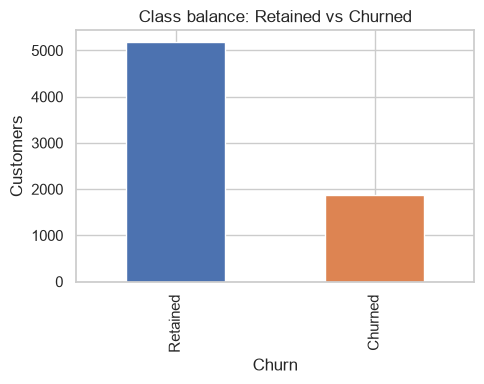

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
df["Churn"].map({0: "Retained", 1: "Churned"}).value_counts().plot(
    kind="bar", color=["#4C72B0", "#DD8452"], ax=ax
)
ax.set_title("Class balance: Retained vs Churned")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig("class_balance.png", dpi=110)
plt.show()


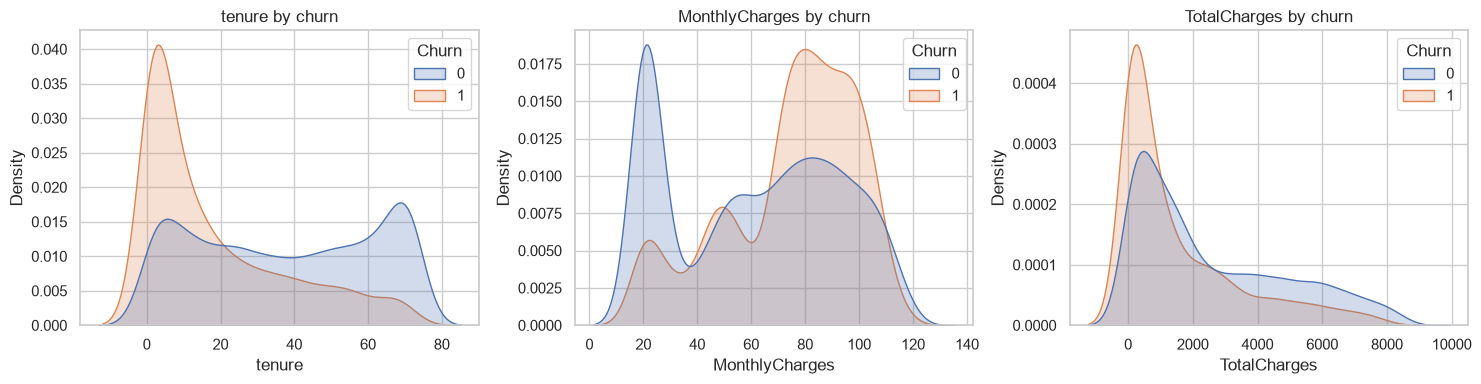

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue="Churn", fill=True, common_norm=False, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig("numeric_distributions.png", dpi=110)
plt.show()


Customers who churn skew heavily toward **low tenure** (they leave early) and
**higher monthly charges**. Long-tenure, low-total-charge customers rarely
churn — consistent with loyalty/contract lock-in.


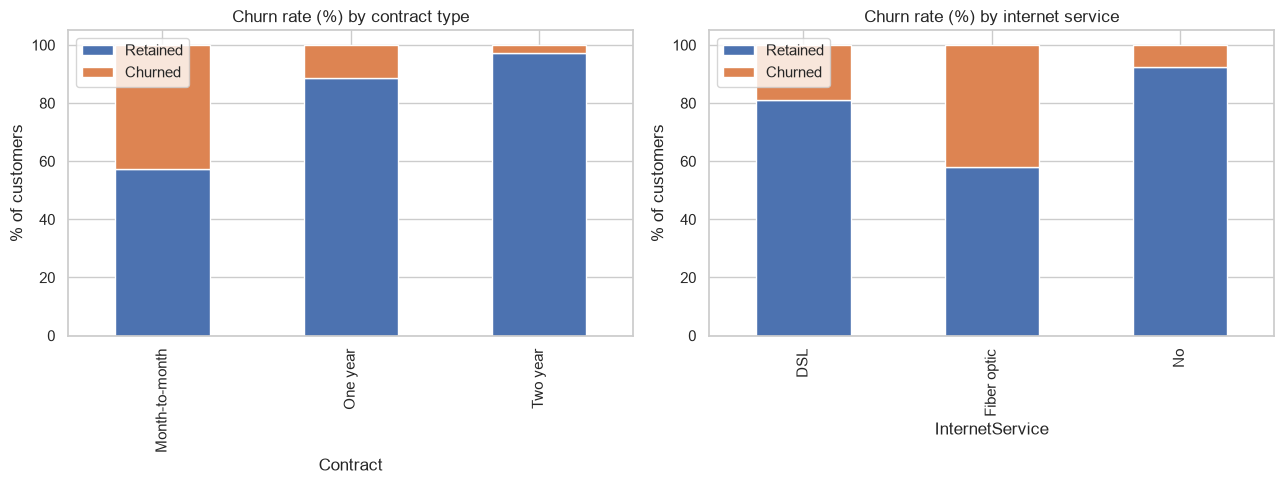

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
contract_churn.rename(columns={0: "Retained", 1: "Churned"}).plot(
    kind="bar", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"]
)
axes[0].set_title("Churn rate (%) by contract type")
axes[0].set_ylabel("% of customers")
axes[0].legend(title="")

internet_churn = pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100
internet_churn.rename(columns={0: "Retained", 1: "Churned"}).plot(
    kind="bar", stacked=True, ax=axes[1], color=["#4C72B0", "#DD8452"]
)
axes[1].set_title("Churn rate (%) by internet service")
axes[1].set_ylabel("% of customers")
axes[1].legend(title="")

plt.tight_layout()
plt.savefig("categorical_churn_rates.png", dpi=110)
plt.show()


Two strong signals stand out immediately:
- **Month-to-month contracts churn far more than one/two-year contracts** —
  no cancellation penalty means less friction to leave.
- **Fibre-optic internet customers churn more than DSL customers** — likely a
  mix of price sensitivity and service reliability complaints.


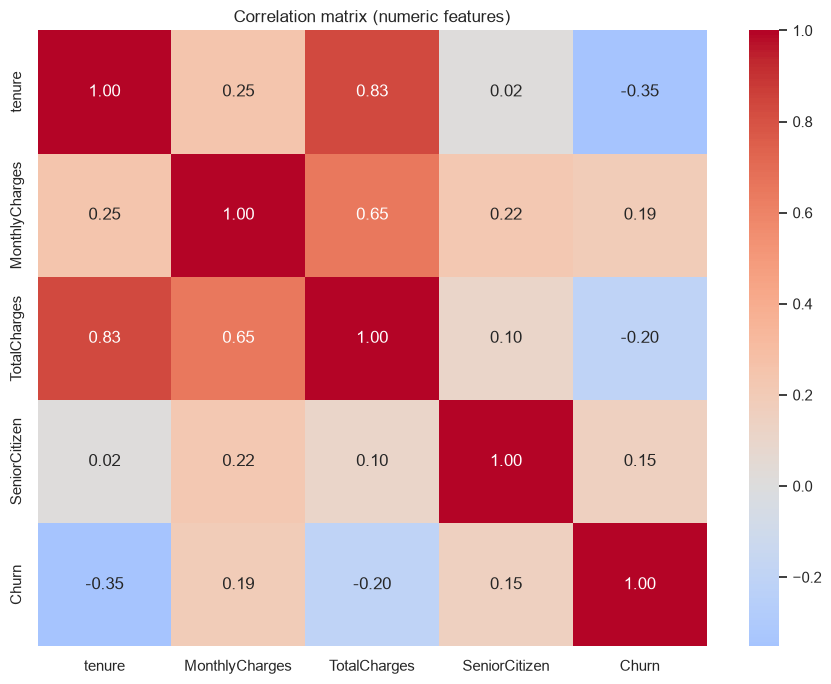

In [9]:
plt.figure(figsize=(9, 7))
numeric_df = df.copy()
numeric_df["Churn"] = numeric_df["Churn"].astype(int)
corr = numeric_df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=110)
plt.show()


## 4. Feature engineering & preprocessing

- **Numeric features** (`tenure`, `MonthlyCharges`, `TotalCharges`): median-impute
  the few missing `TotalCharges` values, then standardise.
- **Categorical features** (everything else — gender, contract type, internet
  add-ons, payment method, etc.): most-frequent impute, then one-hot encode.

Both steps are wrapped in a `ColumnTransformer` inside a scikit-learn
`Pipeline`, so preprocessing is fit only on the training split and applied
consistently to the test split (no leakage).


In [10]:
target = "Churn"
X = df.drop(columns=[target])
y = df[target]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])


Train: (5634, 19)  Test: (1409, 19)


## 5. Baseline models

Five classifiers are trained through the same pipeline and compared on the
held-out test set: Logistic Regression, Decision Tree, Random Forest,
Gradient Boosting and an RBF-kernel SVM. `class_weight="balanced"` is used
for every model that supports it, to counter the 73/27 class imbalance.


In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
}

rows = []
fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results_df = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
results_df.round(3)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.806,0.674,0.524,0.589,0.843
Logistic Regression,0.737,0.503,0.783,0.613,0.841
Decision Tree,0.741,0.508,0.791,0.619,0.829
SVM (RBF),0.745,0.513,0.773,0.617,0.821
Random Forest,0.768,0.555,0.639,0.594,0.821


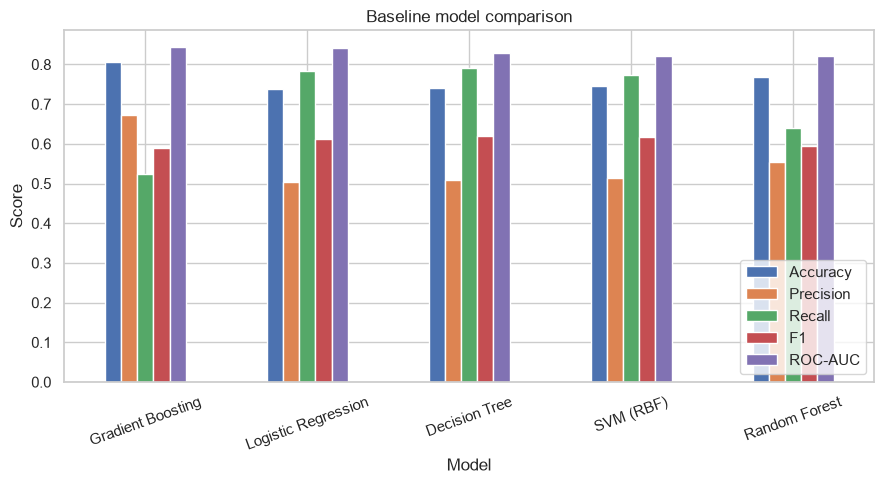

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=ax)
ax.set_title("Baseline model comparison")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=110)
plt.show()


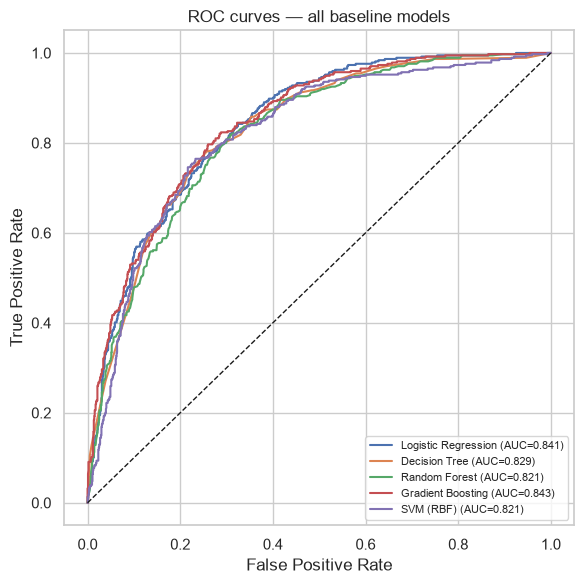

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves — all baseline models")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=110)
plt.show()


**Gradient Boosting** gives the best ROC-AUC, with Logistic Regression close
behind despite being by far the simplest model — a good sign that the
underlying relationships are fairly linear/monotonic (consistent with the EDA:
tenure and contract type dominate). Gradient Boosting is carried forward and
tuned with grid search.


## 6. Hyperparameter tuning (Gradient Boosting)

A 5-fold grid search optimises `n_estimators`, `learning_rate` and `max_depth`
for ROC-AUC.


In [14]:
param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_depth": [2, 3],
}
gb_pipe = Pipeline([("prep", preprocess), ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE))])
grid = GridSearchCV(gb_pipe, param_grid, scoring="roc_auc", cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))


Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200}
Best CV ROC-AUC: 0.8493


In [15]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, proba),
}
print(pd.Series(tuned_metrics).round(4))
print()
print(classification_report(y_test, pred, target_names=["Retained", "Churned"]))


Accuracy     0.7991
Precision    0.6608
Recall       0.5000
F1           0.5693
ROC-AUC      0.8457
dtype: float64

              precision    recall  f1-score   support

    Retained       0.83      0.91      0.87      1035
     Churned       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



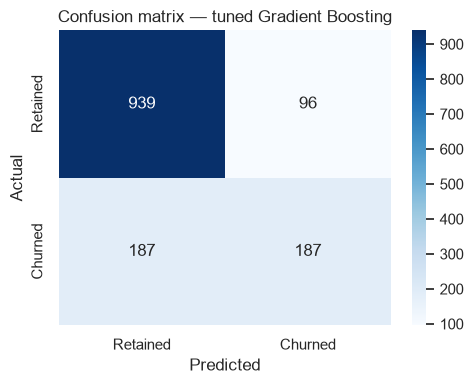

In [16]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix — tuned Gradient Boosting")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=110)
plt.show()


## 7. What drives churn? Feature importance

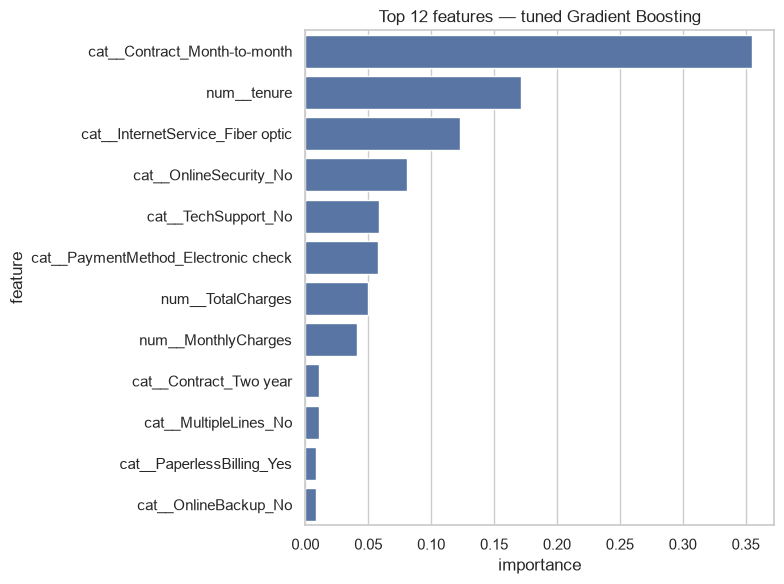

,feature,importance
0,cat__Contract_Month-to-month,0.354812
1,num__tenure,0.171179
2,cat__InternetService_Fiber optic,0.122892
3,cat__OnlineSecurity_No,0.081140
4,cat__TechSupport_No,0.058262
5,cat__PaymentMethod_Electronic check,0.057451
6,num__TotalCharges,0.049998
7,num__MonthlyCharges,0.041190
8,cat__Contract_Two year,0.010746
9,cat__MultipleLines_No,0.010440


In [17]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["clf"].feature_importances_
importance_df = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=importance_df, x="importance", y="feature", ax=ax, color="#4C72B0")
ax.set_title("Top 12 features — tuned Gradient Boosting")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=110)
plt.show()
importance_df.reset_index(drop=True)


The top drivers of churn, in order, are:

1. **Contract = Month-to-month** — by far the strongest signal.
2. **Tenure** — newer customers are far more likely to leave.
3. **Internet service = Fibre optic** — correlates with higher churn.
4. **No online security add-on**
5. **No tech support add-on**
6. **Payment method = Electronic check**

This lines up exactly with the EDA in Section 3: customers on flexible,
no-commitment contracts, without support add-ons, are the highest-risk
segment.


## 8. Conclusion

A tuned Gradient Boosting classifier predicts customer churn on this dataset
with **~80% accuracy and ROC-AUC ≈ 0.85**, meaningfully ahead of a
majority-class baseline (~73% accuracy by always predicting "retained", with
no ability to rank at-risk customers). Recall on the churn class trades off
against precision, as expected given class imbalance and the low separability
of some customers near the decision boundary — a business deploying this
model would pick an operating threshold based on the cost of a missed churner
vs. the cost of an unnecessary retention offer.

**Actionable takeaways for a retention team:**
- Prioritise outreach to **new, month-to-month customers** — they are the
  highest-risk segment.
- Offering **online security / tech support bundles** appears to correlate
  with retention and is a cheap lever to test.
- Consider incentivising a move from **month-to-month to annual contracts**,
  since contract type is the single strongest churn predictor.

**Possible extensions:** SMOTE-based resampling, cost-sensitive thresholding,
SHAP-based per-customer explanations, and periodic retraining as the customer
base evolves.
